In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
from IPython.display import display
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import csv

df = pd.read_csv(
    "cardio_cleaned.csv",
    sep=",",
    engine="python",
    quoting=csv.QUOTE_MINIMAL
)

print("Dataset Shape:", df.shape)
display(df.head())
print(df.dtypes)
df.info()

Dataset Shape: (68666, 13)


,age,gender,height,weight,ap_hi,ap_lo,cholesterol,gluc,smoke,alco,active,cardio,age_years
0,18393,2,168.0,62.0,110,80,1,1,0,0,1,0,50.4
1,20228,1,156.0,85.0,140,90,3,1,0,0,1,1,55.4
2,18857,1,165.0,64.0,130,70,3,1,0,0,0,1,51.6
3,17623,2,169.0,82.0,150,100,1,1,0,0,1,1,48.2
4,17474,1,156.0,56.0,100,60,1,1,0,0,0,0,47.8


age              int64
gender           int64
height         float64
weight         float64
ap_hi            int64
ap_lo            int64
cholesterol      int64
gluc             int64
smoke            int64
alco             int64
active           int64
cardio           int64
age_years      float64
dtype: object
<class 'pandas.DataFrame'>
RangeIndex: 68666 entries, 0 to 68665
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   age          68666 non-null  int64  
 1   gender       68666 non-null  int64  
 2   height       68639 non-null  float64
 3   weight       68660 non-null  float64
 4   ap_hi        68666 non-null  int64  
 5   ap_lo        68666 non-null  int64  
 6   cholesterol  68666 non-null  int64  
 7   gluc         68666 non-null  int64  
 8   smoke        68666 non-null  int64  
 9   alco         68666 non-null  int64  
 10  active       68666 non-null  int64  
 11  cardio       68666 non-null  int64  
 

In [8]:
df_eda = df.copy()

df_eda['height'] = df_eda['height'].fillna(
    df_eda['height'].median()
)

df_eda['weight'] = df_eda['weight'].fillna(
    df_eda['weight'].median()
)

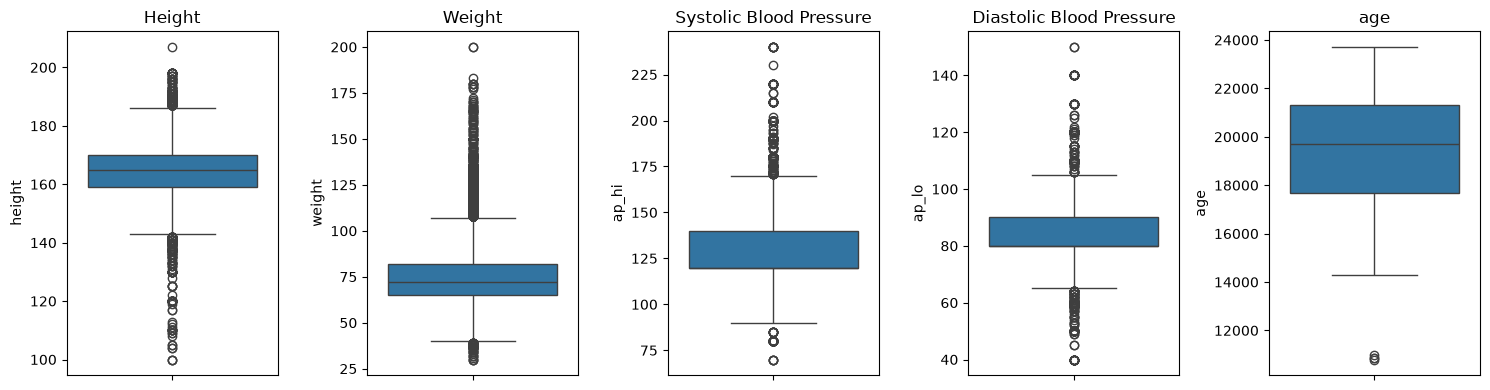

In [3]:
fig, axes = plt.subplots(1, 5, figsize=(15, 4))

sns.boxplot(y=df["height"], ax=axes[0])
axes[0].set_title("Height")

sns.boxplot(y=df["weight"], ax=axes[1])
axes[1].set_title("Weight")

sns.boxplot(y=df["ap_hi"], ax=axes[2])
axes[2].set_title("Systolic Blood Pressure")

sns.boxplot(y=df["ap_lo"], ax=axes[3])
axes[3].set_title("Diastolic Blood Pressure")

sns.boxplot(y=df["age"], ax=axes[4])
axes[4].set_title("age")

plt.tight_layout()
plt.show()

,feature,Q1,Q3,IQR,lower_bound,upper_bound,potential_outliers
0,age,17658.0,21324.0,3666.0,12159.0,26823.0,4
1,height,159.0,170.0,11.0,142.5,186.5,478
2,weight,65.0,82.0,17.0,39.5,107.5,1739
3,ap_hi,120.0,140.0,20.0,90.0,170.0,1005
4,ap_lo,80.0,90.0,10.0,65.0,105.0,3499


C:\Users\mg050\AppData\Local\Temp\ipykernel_22180\4074449832.py:28: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df[col].dropna(), vert=False )


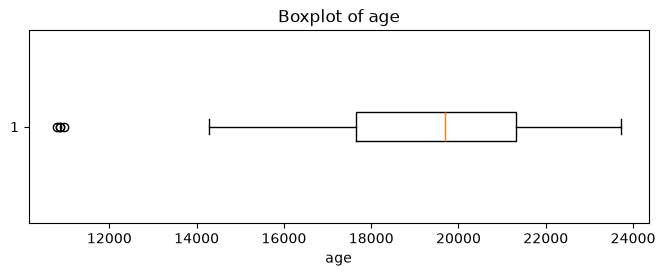

C:\Users\mg050\AppData\Local\Temp\ipykernel_22180\4074449832.py:28: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df[col].dropna(), vert=False )


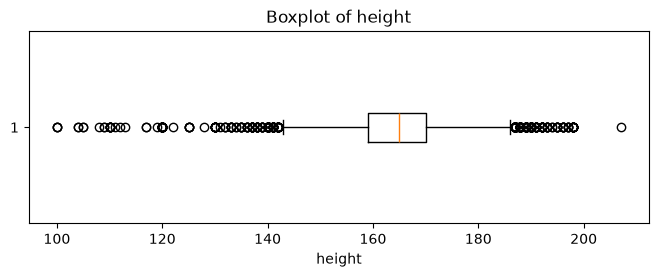

C:\Users\mg050\AppData\Local\Temp\ipykernel_22180\4074449832.py:28: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df[col].dropna(), vert=False )


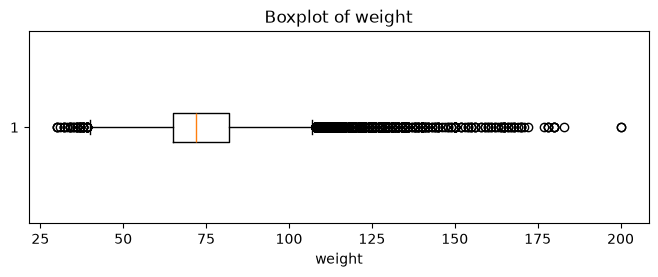

C:\Users\mg050\AppData\Local\Temp\ipykernel_22180\4074449832.py:28: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df[col].dropna(), vert=False )


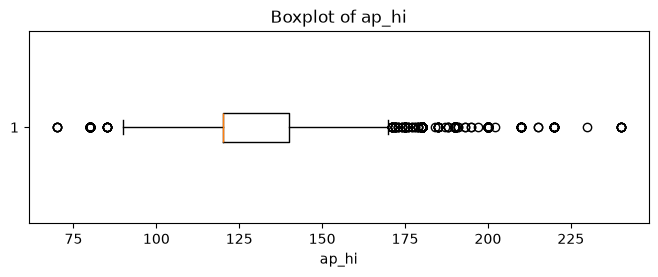

C:\Users\mg050\AppData\Local\Temp\ipykernel_22180\4074449832.py:28: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(df[col].dropna(), vert=False )


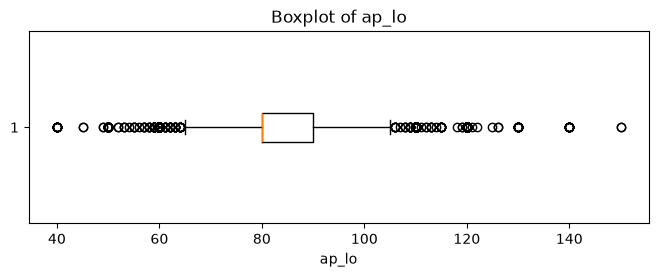

In [4]:
outlier_rows = []

for col in ["age", "height", "weight","ap_hi", "ap_lo"]:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    count = ((df[col] < lower) | (df[col] > upper)).sum()

    outlier_rows.append({
        "feature": col,
        "Q1": q1,
        "Q3": q3,
        "IQR": iqr,
        "lower_bound": lower,
        "upper_bound": upper,
        "potential_outliers": count
    })

outlier_summary = pd.DataFrame(outlier_rows)
display(outlier_summary)

for col in ["age", "height", "weight","ap_hi", "ap_lo"]:
    plt.figure(figsize=(8, 2.5))
    plt.boxplot(df[col].dropna(), vert=False )
    plt.title(f"Boxplot of {col}")
    plt.xlabel(col)
    plt.show()

It is evident that the distribution of ages, heights, and weights became natural and logical within human limits after removing outliers, and blood pressure readings were confined to reasonable ranges.

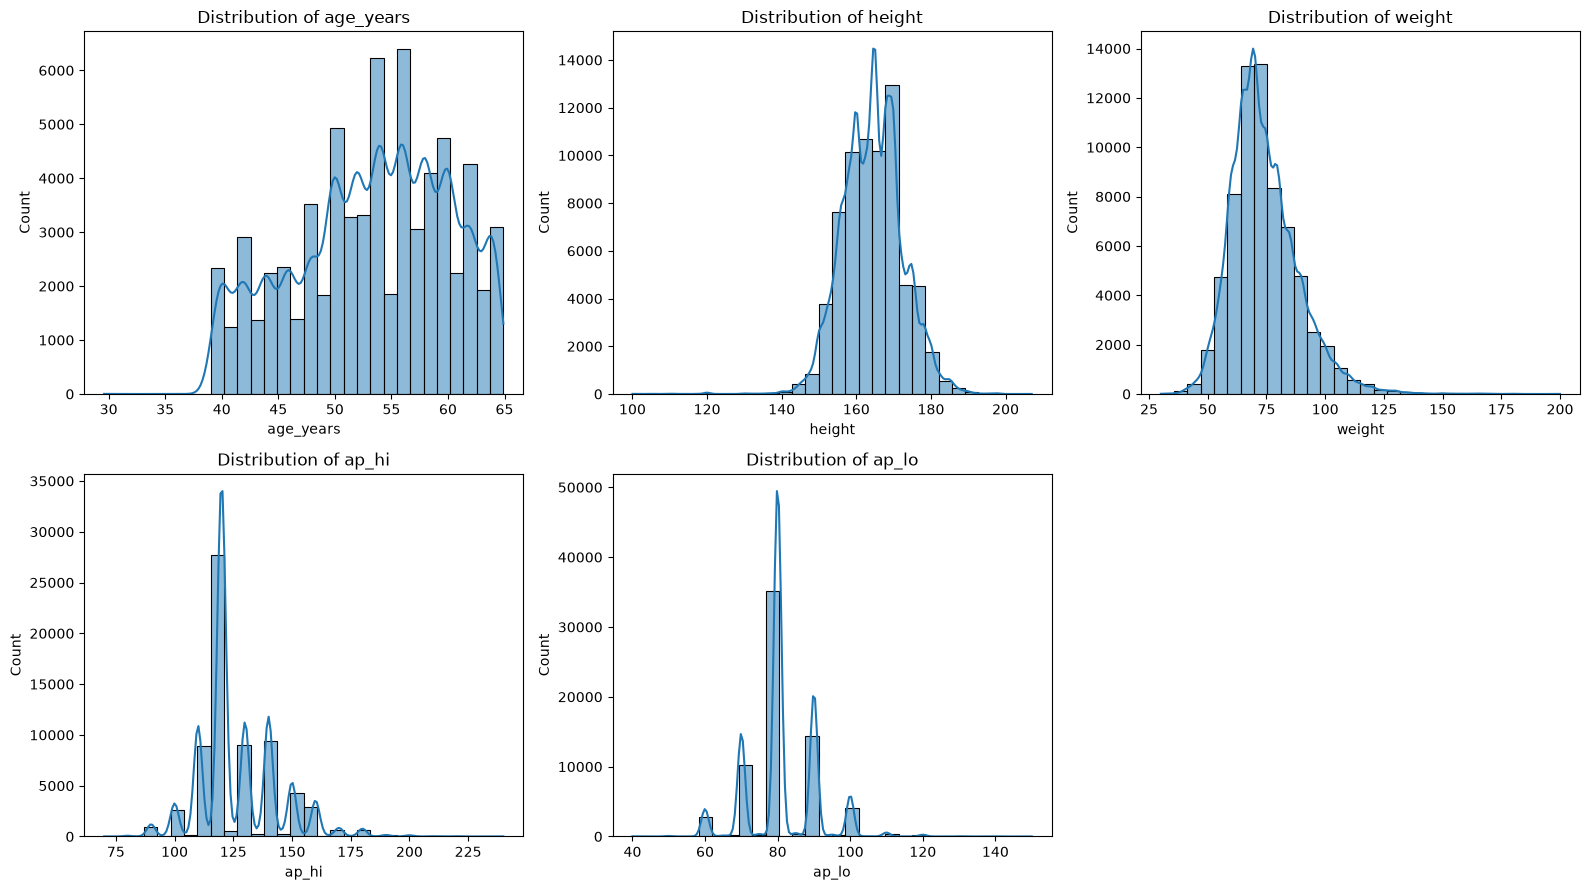

In [5]:
continuous_cols = [
    'age_years', 'height', 'weight', 'ap_hi', 'ap_lo'
]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, col in enumerate(continuous_cols):
    sns.histplot(data=df, x=col, bins=30, kde=True, ax=axes[i])
    axes[i].set_title(f'Distribution of {col}')

axes[-1].set_visible(False)
plt.tight_layout()
plt.show()

It is clear that the data is perfectly balanced, as the number of healthy cases (0) and patients (1) approaches approximately 35,000 cases for each group equally.

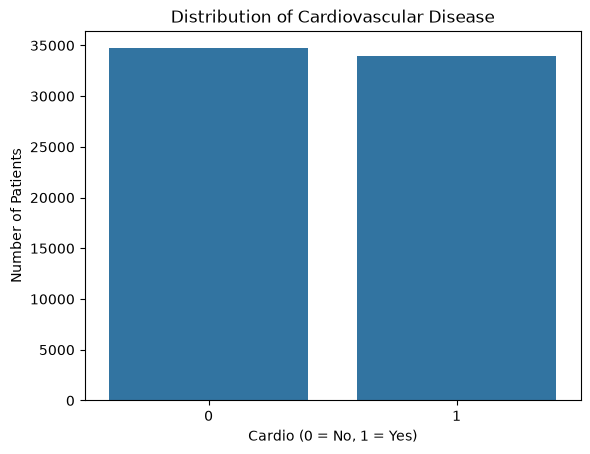

cardio
0    34697
1    33969
Name: count, dtype: int64
cardio
0    50.53
1    49.47
Name: proportion, dtype: float64


In [6]:
sns.countplot(data=df, x='cardio')
plt.title('Distribution of Cardiovascular Disease')
plt.xlabel('Cardio (0 = No, 1 = Yes)')
plt.ylabel('Number of Patients')
plt.show()

print(df['cardio'].value_counts())
print(df['cardio'].value_counts(normalize=True).mul(100).round(2))

In [7]:
compare_cols = [
    'age_years', 'height', 'weight', 'ap_hi', 'ap_lo'
]

print(df.groupby('cardio')[compare_cols].mean().round(2).T)

cardio          0       1
age_years   51.69   54.93
height     164.49  164.30
weight      71.57   76.73
ap_hi      119.60  133.89
ap_lo       78.12   84.55


It shows that the averages of age, weight, and blood pressure (systolic and diastolic) are significantly higher in patients (cardio = 1) compared to healthy individuals (cardio = 0), while the average height is close between the two groups.

C:\Users\mg050\AppData\Local\Temp\ipykernel_22180\685953396.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='cardio', y=col, errorbar=None, palette='Set2',ax=axes[i])
C:\Users\mg050\AppData\Local\Temp\ipykernel_22180\685953396.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='cardio', y=col, errorbar=None, palette='Set2',ax=axes[i])
C:\Users\mg050\AppData\Local\Temp\ipykernel_22180\685953396.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df, x='cardio', y=col, errorbar=None, palette='Set2',ax=axes[i])
C

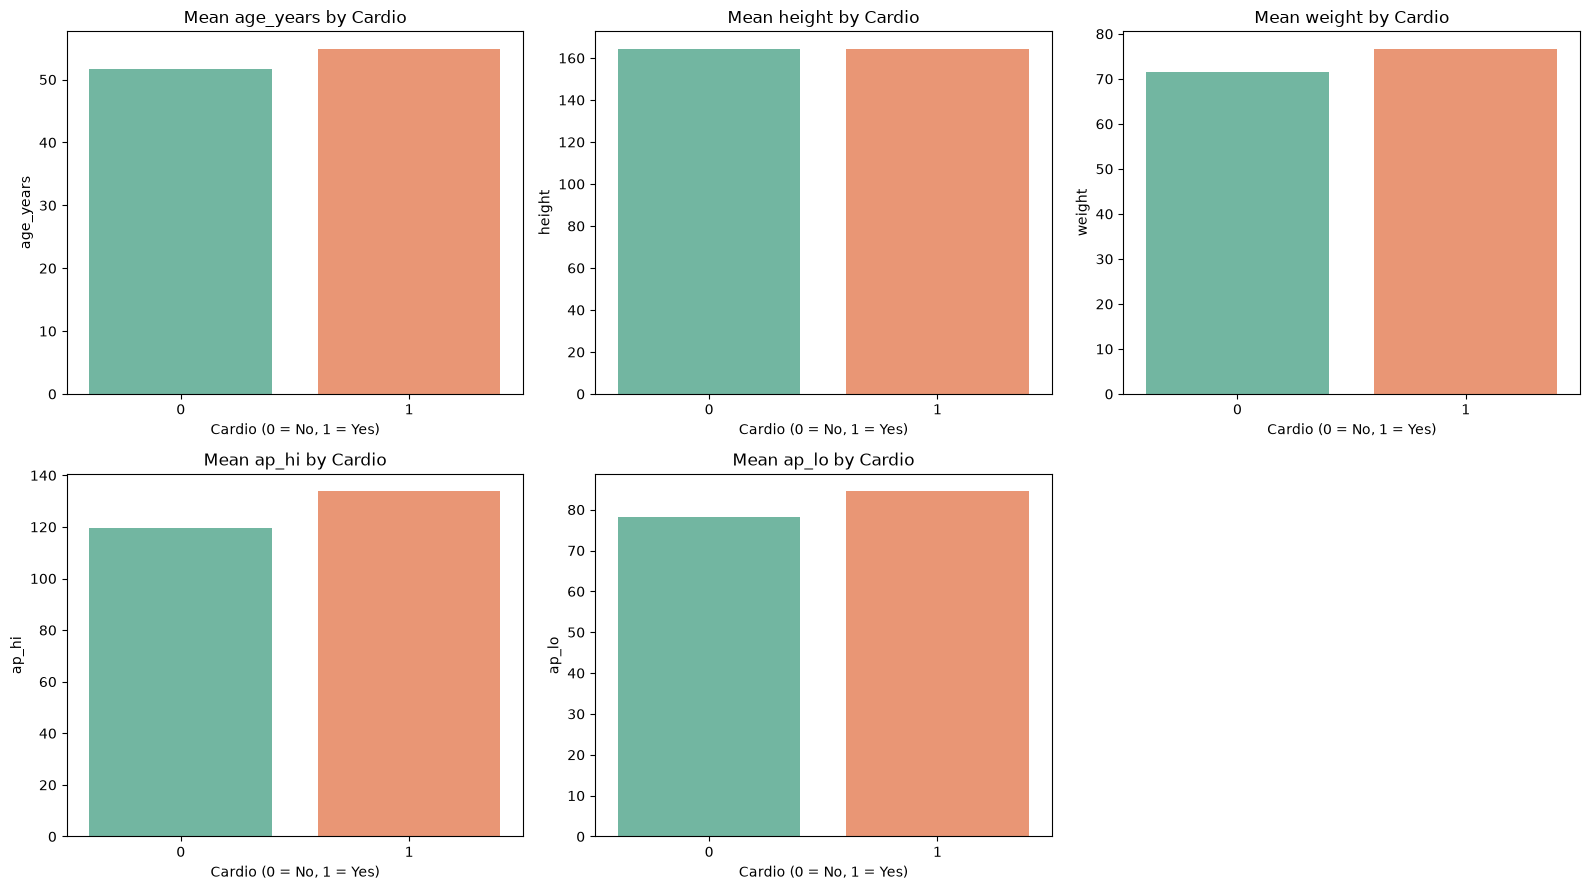

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, col in enumerate(compare_cols):
    sns.barplot(data=df, x='cardio', y=col, errorbar=None, palette='Set2',ax=axes[i])
    axes[i].set_title(f'Mean {col} by Cardio')
    axes[i].set_xlabel('Cardio (0 = No, 1 = Yes)')

axes[-1].set_visible(False)
plt.tight_layout()
plt.show()

How is the incidence rate of heart disease affected by categorical factors (cholesterol, glucose, smoking, physical activity, gender)? It is evident that the probability of developing heart disease increases sharply and dangerously with rising levels of cholesterol and glucose (especially when moving to the third level 3).

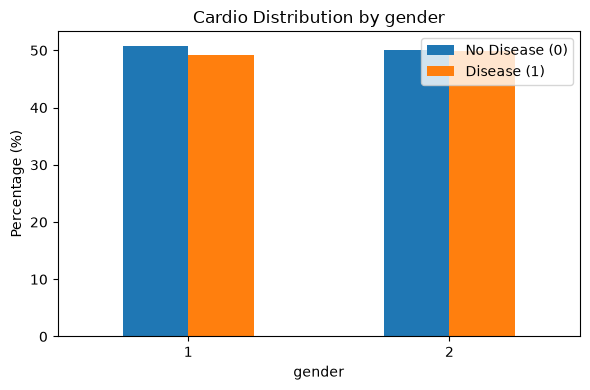

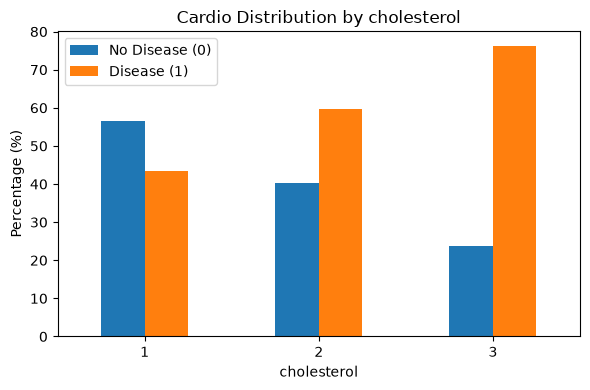

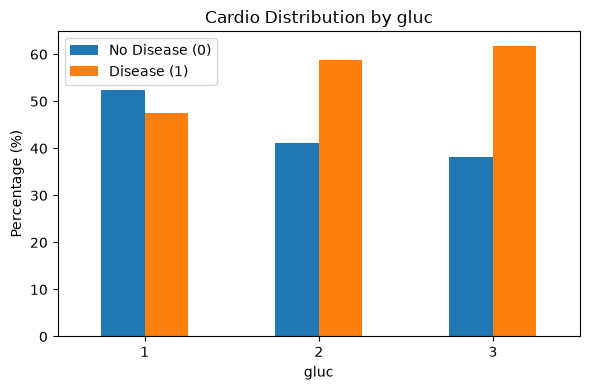

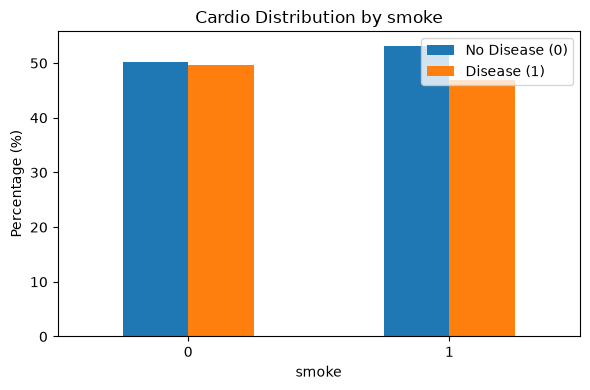

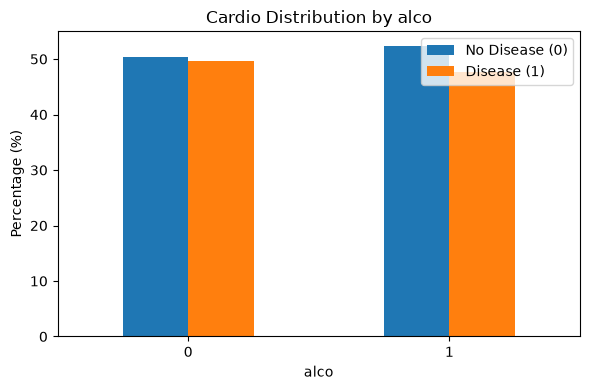

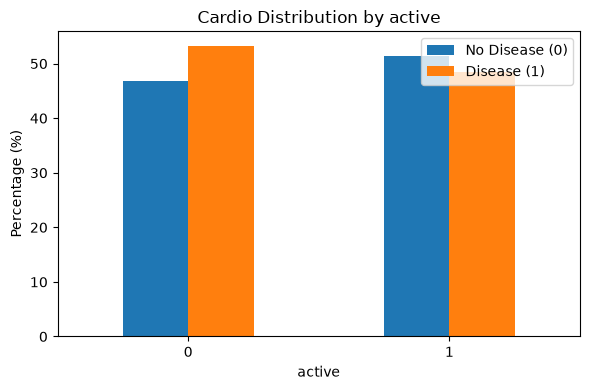

In [9]:
categorical_cols = [
    'gender', 'cholesterol', 'gluc',
    'smoke', 'alco', 'active'
]

for col in categorical_cols:
    rates = pd.crosstab(
        df[col],
        df['cardio'],
        normalize='index'
    ) * 100

    rates.plot(kind='bar', figsize=(6, 4))
    plt.title(f'Cardio Distribution by {col}')
    plt.xlabel(col)
    plt.ylabel('Percentage (%)')
    plt.legend(['No Disease (0)', 'Disease (1)'])
    plt.xticks(rotation=0)
    plt.tight_layout()
    plt.show()

The boxplot demonstrates that the median age and blood pressure clearly increase in patients, and it shows the spread and concentration of data for each category.

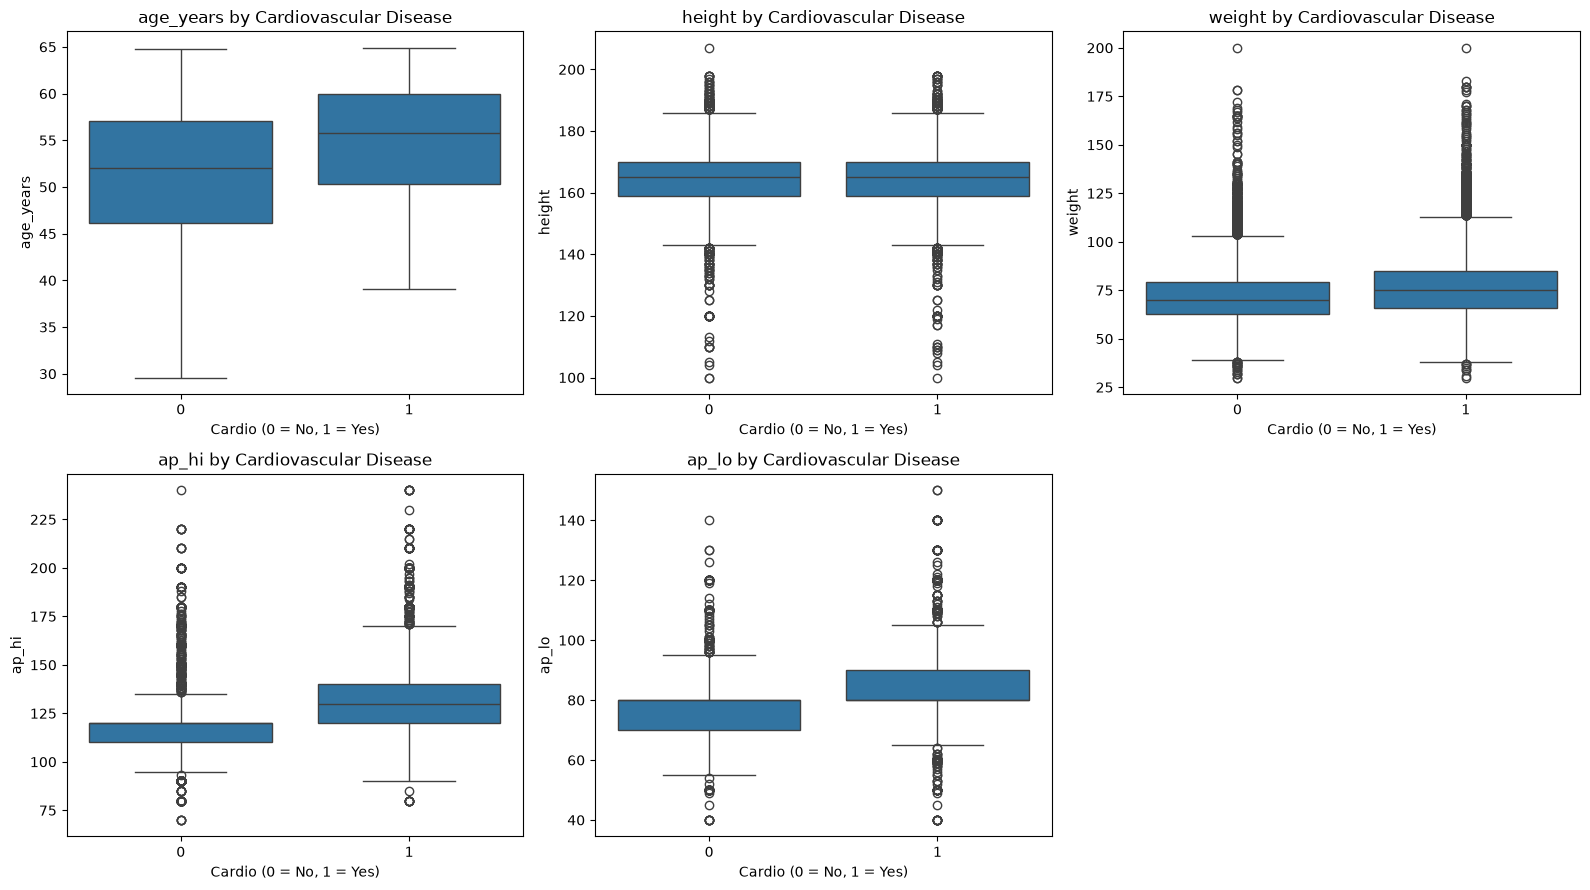

In [10]:
continuous_cols = [
    'age_years', 'height', 'weight', 'ap_hi', 'ap_lo'
]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, col in enumerate(continuous_cols):
    sns.boxplot(data=df, x='cardio', y=col, ax=axes[i])
    axes[i].set_title(f'{col} by Cardiovascular Disease')
    axes[i].set_xlabel('Cardio (0 = No, 1 = Yes)')

axes[-1].set_visible(False)
plt.tight_layout()
plt.show()

It illustrates the distribution of the Body Mass Index (BMI) for patients, where most of the distribution is concentrated around normal values and overweight (between 25 and 30), with a tail extending towards higher values (severe obesity).

It shows that the average BMI is higher in patients with heart disease (cardio = 1) compared to healthy individuals (cardio = 0).

Systolic (ap_hi) and Diastolic (ap_lo) blood pressure have the strongest positive correlation with heart disease, making them the most critical predictors.
Age (age_years) and Cholesterol follow closely as significant risk factors.
BMI and Weight show moderate positive correlation.
Height shows almost no correlation with heart disease.

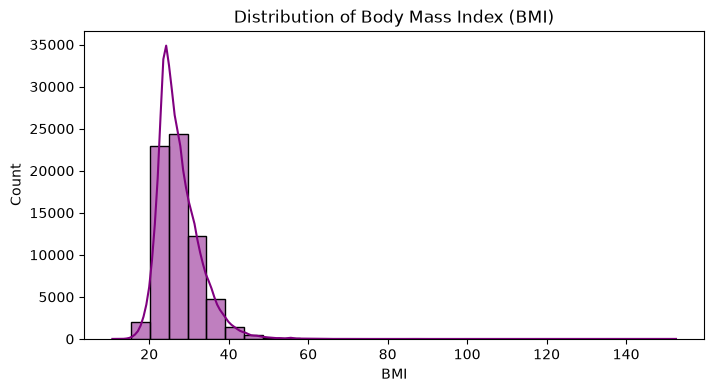

C:\Users\mg050\AppData\Local\Temp\ipykernel_22180\1785464699.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='cardio', y='bmi', data=df, palette='Set2')


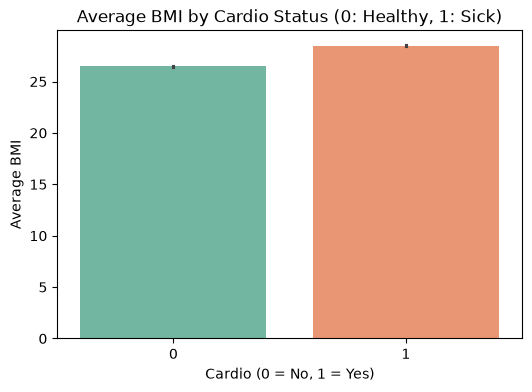

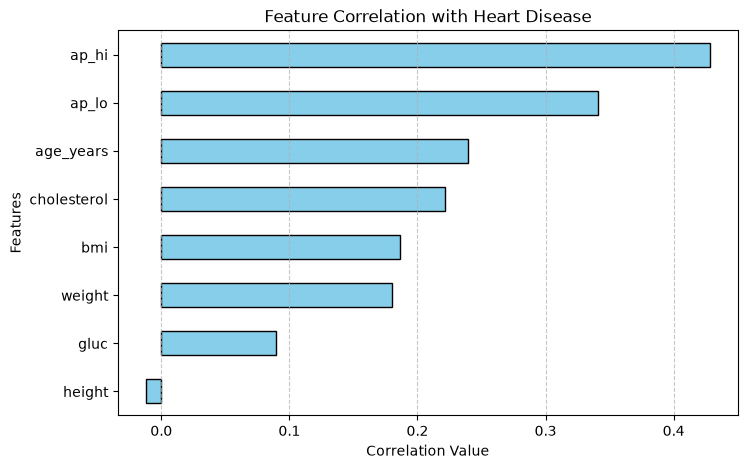

In [26]:
import seaborn as sns
import matplotlib.pyplot as plt

df['bmi'] = df['weight'] / ((df['height'] / 100) ** 2)


plt.figure(figsize=(8, 4))
sns.histplot(df['bmi'].dropna(), bins=30, kde=True, color='purple')
plt.title('Distribution of Body Mass Index (BMI)')
plt.xlabel('BMI')
plt.ylabel('Count')
plt.show()


plt.figure(figsize=(6, 4))
sns.barplot(x='cardio', y='bmi', data=df, palette='Set2')
plt.title('Average BMI by Cardio Status (0: Healthy, 1: Sick)')
plt.xlabel('Cardio (0 = No, 1 = Yes)')
plt.ylabel('Average BMI')
plt.show()


correlations = df[['age_years', 'height', 'weight', 'ap_hi', 'ap_lo', 'cholesterol', 'gluc', 'bmi']].apply(lambda x: x.corr(df['cardio']))
plt.figure(figsize=(8, 5))
correlations.sort_values().plot(kind='barh', color='skyblue', edgecolor='black')
plt.title('Feature Correlation with Heart Disease')
plt.xlabel('Correlation Value')
plt.ylabel('Features')
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.show()